# Data preprocessing - Beijing PM2.5

Project 19 (air quality forecasting via gradient boosting and LSTM models) - Team T024, Section A.

This notebook walks through the preprocessing pipeline one step at a time. Every step calls the same
functions as `python -m aqf.data.pipeline` (`src/aqf/data`), so the notebook and the pipeline cannot drift
apart. Settings live in `configs/data.yaml`. The full write-up is `reports/preprocessing/preprocessing.pdf`.

| Step | What | Why |
|---|---|---|
| 1 | load and validate | fail loudly on schema, grid or weather problems |
| 2 | audit the target | missingness, gaps, skew, extremes |
| 3 | decode `Iws` | it is a running total, not wind speed |
| 4 | snow / rain flags | `Is` / `Ir` are consecutive-hour counters |
| 5 | one-hot wind direction | fixed column order across folds |
| 6 | missing target | untouched label + flag + causal input copy |
| 7 | log1p | reduce skew of the target and wind columns |
| 8 | chronological folds | expanding window, 24 h embargo, 2014 held out |
| 9 | scaling | statistics from training rows only |
| 10 | full pipeline run | writes the artifacts used by the models |

## 0. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd

from aqf import viz
from aqf.config import load_config
from aqf.data.audit import gaps
from aqf.data.clean import clean, decode_precip, decode_wind, encode_dir, fill_target
from aqf.data.load import load_raw
from aqf.data.pipeline import run
from aqf.data.scale import Scaler
from aqf.data.split import fold_mask, make_folds

%config InlineBackend.figure_format = "retina"
pd.set_option("display.width", 120)
viz.use_style()

cfg = load_config("configs/data.yaml")
{k: cfg[k] for k in ["clean", "split", "scale"]}

{'clean': {'ffill_limit': 3, 'wind_dirs': ['NE', 'NW', 'SE', 'cv']},
 'split': {'val_years': [2011, 2012, 2013],
  'test_year': 2014,
  'gap_hours': 24},
 'scale': {'cols': ['pm25',
   'pm25_in',
   'dewp',
   'temp',
   'pres',
   'ws',
   'ws_cum',
   'snow_cum',
   'rain_cum'],
  'log': ['pm25', 'pm25_in', 'ws', 'ws_cum', 'snow_cum', 'rain_cum']}}

## 1. Load and validate

`load_raw` reads the csv, renames columns, builds a timestamp index from year / month / day / hour and stops
with an error if the column list changes, the hourly grid has holes or duplicates, or any weather value is
missing. Only `pm25` is allowed to be missing.

In [2]:
raw = load_raw(cfg["paths"]["raw"])
print(raw.shape, raw.index.min(), "->", raw.index.max())
raw.head()

(43824, 8) 2010-01-01 00:00:00 -> 2014-12-31 23:00:00


,pm25,dewp,temp,pres,cbwd,ws_cum,snow_cum,rain_cum
ts,,,,,,,,
2010-01-01 00:00:00,NaN,-21,-11.0,1021.0,NW,1.79,0,0
2010-01-01 01:00:00,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2010-01-01 02:00:00,NaN,-21,-11.0,1019.0,NW,6.71,0,0
2010-01-01 03:00:00,NaN,-21,-14.0,1019.0,NW,9.84,0,0
2010-01-01 04:00:00,NaN,-20,-12.0,1018.0,NW,12.97,0,0


In [3]:
raw.isna().sum().rename("missing").to_frame().T

,pm25,dewp,temp,pres,cbwd,ws_cum,snow_cum,rain_cum
missing,2067,0,0,0,0,0,0,0


## 2. Audit the target

Summary numbers, missing hours per year and the length of every gap.

In [4]:
pm = raw["pm25"]
pd.Series({
    "missing hours": pm.isna().sum(),
    "missing %": round(pm.isna().mean() * 100, 2),
    "median": pm.median(),
    "p99": pm.quantile(0.99),
    "max": pm.max(),
    "skew": round(pm.skew(), 2),
}).to_frame("pm25").T

,missing hours,missing %,median,p99,max,skew
pm25,2067.0,4.72,72.0,420.0,994.0,1.8


In [5]:
pm.isna().groupby(raw.index.year).sum().rename("missing hours").to_frame().T

ts,2010,2011,2012,2013,2014
missing hours,669,728,489,82,99


In [6]:
g = gaps(pm.isna())
pd.Series({
    "gaps": len(g),
    "1 h": (g["size"] == 1).sum(),
    "<= 3 h": (g["size"] <= 3).sum(),
    "> 24 h": (g["size"] > 24).sum(),
    "longest (h)": g["size"].max(),
    "longest starts": g.loc[g["size"].idxmax(), "start"],
}).to_frame("pm25 gaps").T

,gaps,1 h,<= 3 h,> 24 h,longest (h),longest starts
pm25 gaps,214,112,143,20,155,2010-09-21 05:00:00


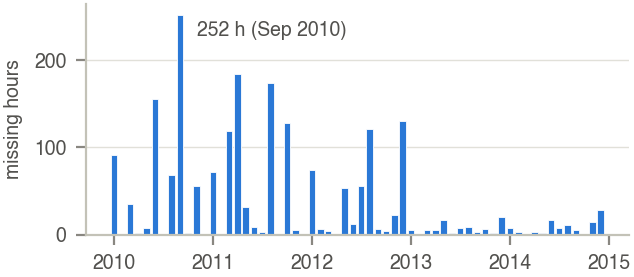

In [7]:
viz.missing_by_month(raw.assign(pm25_miss=pm.isna().astype("int8")));

Missingness falls sharply after 2012, so the early folds train on the noisiest years.

**Extremes.** The two highest values fall in the first hours of the Lunar New Year (23 Jan 2012 and
14 Feb 2010). The neighbouring hours rise and fall with them, so they are real episodes and are kept.

In [8]:
pd.concat([
    raw.loc[t - pd.Timedelta("2h"): t + pd.Timedelta("2h"), ["pm25", "cbwd"]]
    for t in pm.nlargest(3).index[[0, 1]]
])

,pm25,cbwd
ts,,
2012-01-22 23:00:00,161.0,cv
2012-01-23 00:00:00,225.0,NW
2012-01-23 01:00:00,994.0,NW
2012-01-23 02:00:00,972.0,NW
2012-01-23 03:00:00,430.0,NW
2010-02-13 23:00:00,267.0,cv
2010-02-14 00:00:00,351.0,NE
2010-02-14 01:00:00,980.0,cv
2010-02-14 02:00:00,NaN,NW


## 3. Decode cumulative wind speed

`Iws` adds up wind speed while the direction stays the same and restarts when `cbwd` changes. The hourly
speed is the difference inside a direction run, and the raw value on the first hour of a run:

$$ws_t = \begin{cases} I_t & d_t \neq d_{t-1} \\ I_t - I_{t-1} & d_t = d_{t-1} \end{cases}$$

In [9]:
df = decode_wind(raw)
df.loc["2010-01-01 12:00":"2010-01-01 18:00", ["cbwd", "ws_cum", "ws"]]

,cbwd,ws_cum,ws
ts,,,
2010-01-01 12:00:00,NW,37.56,3.13
2010-01-01 13:00:00,NW,40.69,3.13
2010-01-01 14:00:00,NW,43.82,3.13
2010-01-01 15:00:00,cv,0.89,0.89
2010-01-01 16:00:00,NW,1.79,1.79
2010-01-01 17:00:00,NW,2.68,0.89
2010-01-01 18:00:00,NE,1.79,1.79


Check: adding the hourly speeds back up inside each run rebuilds `Iws` exactly.

In [10]:
run_id = df["cbwd"].ne(df["cbwd"].shift()).cumsum()
np.allclose(df.groupby(run_id)["ws"].cumsum(), df["ws_cum"])

True

In [11]:
df.groupby("cbwd")["ws"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
cbwd,,,,,,,,
NE,4997.0,2.55,1.67,0.89,0.89,1.79,4.02,11.18
NW,14150.0,4.53,2.97,0.89,1.79,3.13,5.81,20.12
SE,15290.0,2.81,1.41,0.89,1.79,3.13,4.02,13.86
cv,9387.0,0.99,0.49,0.45,0.89,0.89,0.89,7.15


Calm-variable (`cv`) hours average about 1 m/s, which matches the label.

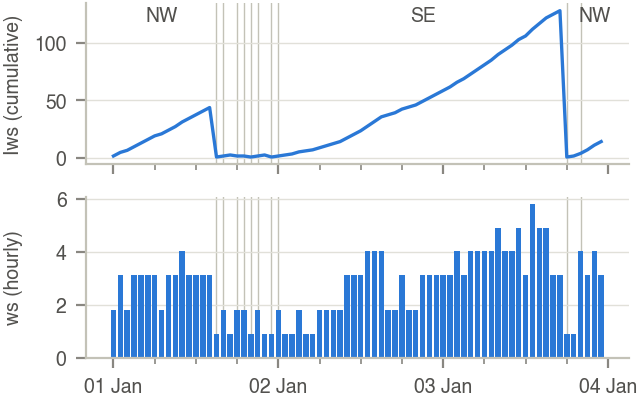

In [12]:
viz.wind_decode(df);

## 4. Snow and rain flags

`Is` and `Ir` count consecutive hours of snow and rain. A positive counter means it is falling now.

In [13]:
df = decode_precip(df)
df[["snow", "rain"]].mean().mul(100).round(2).rename("% of hours").to_frame().T

,snow,rain
% of hours,0.84,4.13


## 5. Wind direction one-hot

Four columns in a fixed order, so column positions never depend on which directions appear in a fold.

In [14]:
df = encode_dir(df, cfg["clean"]["wind_dirs"])
df.filter(like="wd_").sum().rename("hours").to_frame().T

,wd_ne,wd_nw,wd_se,wd_cv
hours,4997,14150,15290,9387


## 6. Missing target: label, flag, causal input

- `pm25` stays untouched. A missing value means that hour is skipped in training loss and evaluation.
- `pm25_miss` records where the value was missing.
- `pm25_in` is the input copy: the last observed value carried forward for at most 3 hours.

Linear interpolation is shown for comparison only. It fills the gap using the value **after** it, which
leaks the future into inputs near the forecast origin.

In [15]:
df = fill_target(df, cfg["clean"]["ffill_limit"])

ex = g[(g["size"] > 3) & (g["size"] <= 6)].iloc[0]
s = ex["start"]
win = df.loc[s - pd.Timedelta("2h"): s + pd.Timedelta(hours=int(ex["size"]) + 1), ["pm25", "pm25_miss", "pm25_in"]]
win.assign(interpolated_leaks=df["pm25"].interpolate(limit_area="inside").loc[win.index].round(1))

,pm25,pm25_miss,pm25_in,interpolated_leaks
ts,,,,
2010-05-27 17:00:00,72.0,0,72.0,72.0
2010-05-27 18:00:00,85.0,0,85.0,85.0
2010-05-27 19:00:00,NaN,1,85.0,85.8
2010-05-27 20:00:00,NaN,1,85.0,86.7
2010-05-27 21:00:00,NaN,1,85.0,87.5
2010-05-27 22:00:00,NaN,1,NaN,88.3
2010-05-27 23:00:00,NaN,1,NaN,89.2
2010-05-28 00:00:00,90.0,0,90.0,90.0
2010-05-28 01:00:00,89.0,0,89.0,89.0


In [16]:
pd.Series({
    "missing labels": df["pm25"].isna().sum(),
    "missing inputs after fill": df["pm25_in"].isna().sum(),
    "input hours recovered": df["pm25"].isna().sum() - df["pm25_in"].isna().sum(),
}).to_frame("hours").T

,missing labels,missing inputs after fill,input hours recovered
hours,2067,1681,386


Steps 3 to 6 together are exactly what the pipeline's `clean` does:

In [17]:
df.equals(clean(raw, cfg["clean"]))

True

## 7. log1p on skewed columns

log1p(x) = ln(1 + x). It turns "times bigger" into "plus a fixed step", so the model judges errors as
percentages and the rare spikes stop dominating the loss. The +1 keeps zeros safe. Predictions are mapped
back with expm1 before computing MAE, RMSE and R2.

In [18]:
cols = ["pm25", "ws", "ws_cum", "snow_cum", "rain_cum"]
pd.DataFrame({"raw skew": df[cols].skew(), "log1p skew": np.log1p(df[cols]).skew()}).round(2).T

,pm25,ws,ws_cum,snow_cum,rain_cum
raw skew,1.8,1.76,4.3,19.48,11.66
log1p skew,-0.3,0.50,0.7,13.05,6.18


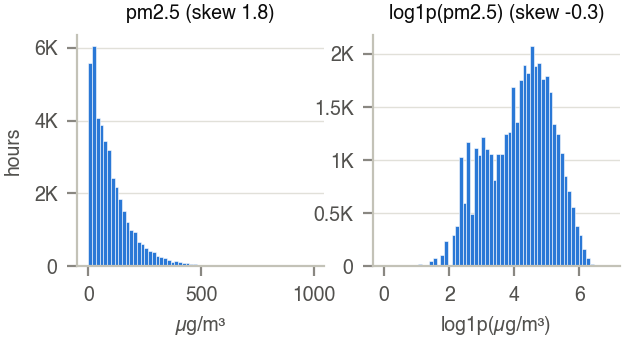

In [19]:
viz.target_hist(df);

## 8. Chronological folds

Fold k evaluates on one calendar year and trains on everything up to 24 hours before it. The 24-hour gap is
an embargo: with gap >= forecast horizon, no training target can fall inside the evaluation year.
2014 is the final test year and is not touched until the end.

In [20]:
folds = make_folds(df.index, **cfg["split"])
pd.DataFrame([{
    "fold": f["name"],
    "train from": f["train"][0],
    "train until (excl.)": f["train"][1],
    "eval from": f["eval"][0],
    "eval until (excl.)": f["eval"][1],
    "train rows": fold_mask(df.index, f["train"]).sum(),
    "labelled eval rows": df.loc[fold_mask(df.index, f["eval"]), "pm25"].notna().sum(),
} for f in folds])

,fold,train from,train until (excl.),eval from,eval until (excl.),train rows,labelled eval rows
0,cv1,2010-01-01,2010-12-31,2011-01-01,2012-01-01,8736,8032
1,cv2,2010-01-01,2011-12-31,2012-01-01,2013-01-01,17496,8295
2,cv3,2010-01-01,2012-12-31,2013-01-01,2014-01-01,26280,8678
3,test,2010-01-01,2013-12-31,2014-01-01,2015-01-01,35040,8661


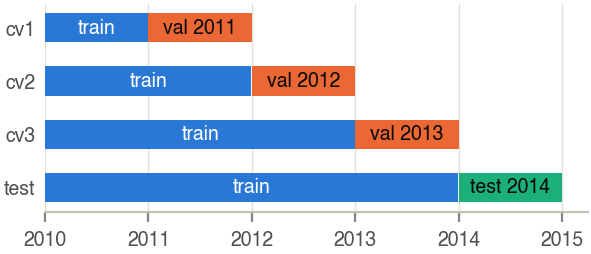

In [21]:
viz.fold_timeline(folds);

## 9. Leak-free scaling

Each fold gets its own scaler, fitted on that fold's training rows only: log1p for the skewed columns, then a
z-score. Shown here for fold `cv1`.

In [22]:
f = folds[0]
tr, ev = fold_mask(df.index, f["train"]), fold_mask(df.index, f["eval"])
sc = Scaler(**cfg["scale"]).fit(df[tr])
stats = pd.DataFrame({"mean": pd.Series(sc.mean), "std": pd.Series(sc.std)}).round(3)
stats.assign(log1p=stats.index.isin(sc.log))

,mean,std,log1p
pm25,4.264,0.950,True
pm25_in,4.264,0.951,True
dewp,1.657,14.364,False
temp,11.683,12.597,False
pres,1016.294,9.645,False
ws,1.256,0.527,True
ws_cum,2.300,1.387,True
snow_cum,0.018,0.194,True
rain_cum,0.077,0.374,True


On the evaluation year the scaled columns are close to, but not exactly, mean 0 and std 1. That is expected:
the statistics come from 2010 only, and nothing from 2011 was used to compute them.

In [23]:
z = sc.transform(df[ev])
z[sc.cols].agg(["mean", "std"]).round(2)

,pm25,pm25_in,dewp,temp,pres,ws,ws_cum,snow_cum,rain_cum
mean,-0.11,-0.11,0.03,0.07,0.11,0.00,-0.03,-0.01,-0.08
std,1.06,1.06,1.01,0.95,1.15,0.99,0.98,0.88,0.75


In [24]:
np.allclose(sc.inverse(z["pm25"], "pm25"), df.loc[ev, "pm25"], equal_nan=True)

True

## 10. Full pipeline run

Writes the cleaned hourly frame, the fold boundaries, one scaler per fold and the audit summary.

In [25]:
out, _ = run(cfg)
print("matches notebook frame:", out.equals(df))
paths = [cfg["paths"]["interim"], *sorted(cfg["paths"]["processed"].rglob("*.json")), cfg["paths"]["qa"]]
[str(p.relative_to(ROOT)) for p in paths]

matches notebook frame: True


['data/interim/hourly.parquet',
 'data/processed/folds.json',
 'data/processed/scalers/cv1.json',
 'data/processed/scalers/cv2.json',
 'data/processed/scalers/cv3.json',
 'data/processed/scalers/test.json',
 'reports/preprocessing/qa.json']

## Summary

- 43,824 hourly rows, complete grid; only `pm25` is missing (4.72%), mostly in 2010-2012.
- `Iws` decoded into hourly wind speed; `Is` / `Ir` into snow / rain flags.
- Label untouched, missing flag added, input copy filled causally for at most 3 hours.
- Expanding-window folds on 2011, 2012, 2013, test on 2014, 24-hour embargo.
- Scalers fitted on training rows only, saved per fold.

Next: feature engineering (lags, rolling means, calendar), persistence and 24-hour seasonal-naive baselines,
then XGBoost.